# 📈 Basic Time Series Forecast Model
**Method:** Rolling-window moving average  |  **Metric:** MAE

| Step | Task |
|---|---|
| 1 | Load historical stock CSV data |
| 2 | Split into train and test periods |
| 3 | Apply rolling-window moving average to predict |
| 4 | Evaluate forecast error (MAE) on test set |
| 5 | Plot actual vs predicted series |

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

CSV_PATH = Path("../data/stock_data.csv")   # <- change to use your own CSV
TARGET = "Close"                            # column to forecast
TRAIN_FRAC = 0.80                           # 80% train / 20% test
OUT_DIR = Path("../outputs"); OUT_DIR.mkdir(exist_ok=True)

## Step 1 — Load historical stock CSV data

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["Date"])
df = df.sort_values("Date").set_index("Date")
assert TARGET in df.columns, f"'{TARGET}' column not found"
assert df[TARGET].notna().all(), "Missing values found - clean them first"

print(f"Rows: {len(df)} | Range: {df.index.min().date()} -> {df.index.max().date()}")
df.head()

Rows: 1500 | Range: 2019-01-01 -> 2024-09-30


,Open,High,Low,Close,Volume
Date,,,,,
2019-01-01,99.89,100.97,99.29,100.47,3692327
2019-01-02,100.34,100.62,98.63,99.06,3530684
2019-01-03,99.32,100.94,98.80,100.15,2466960
2019-01-04,100.22,102.16,99.90,101.53,4047860
2019-01-07,101.49,101.60,98.58,98.85,3872985


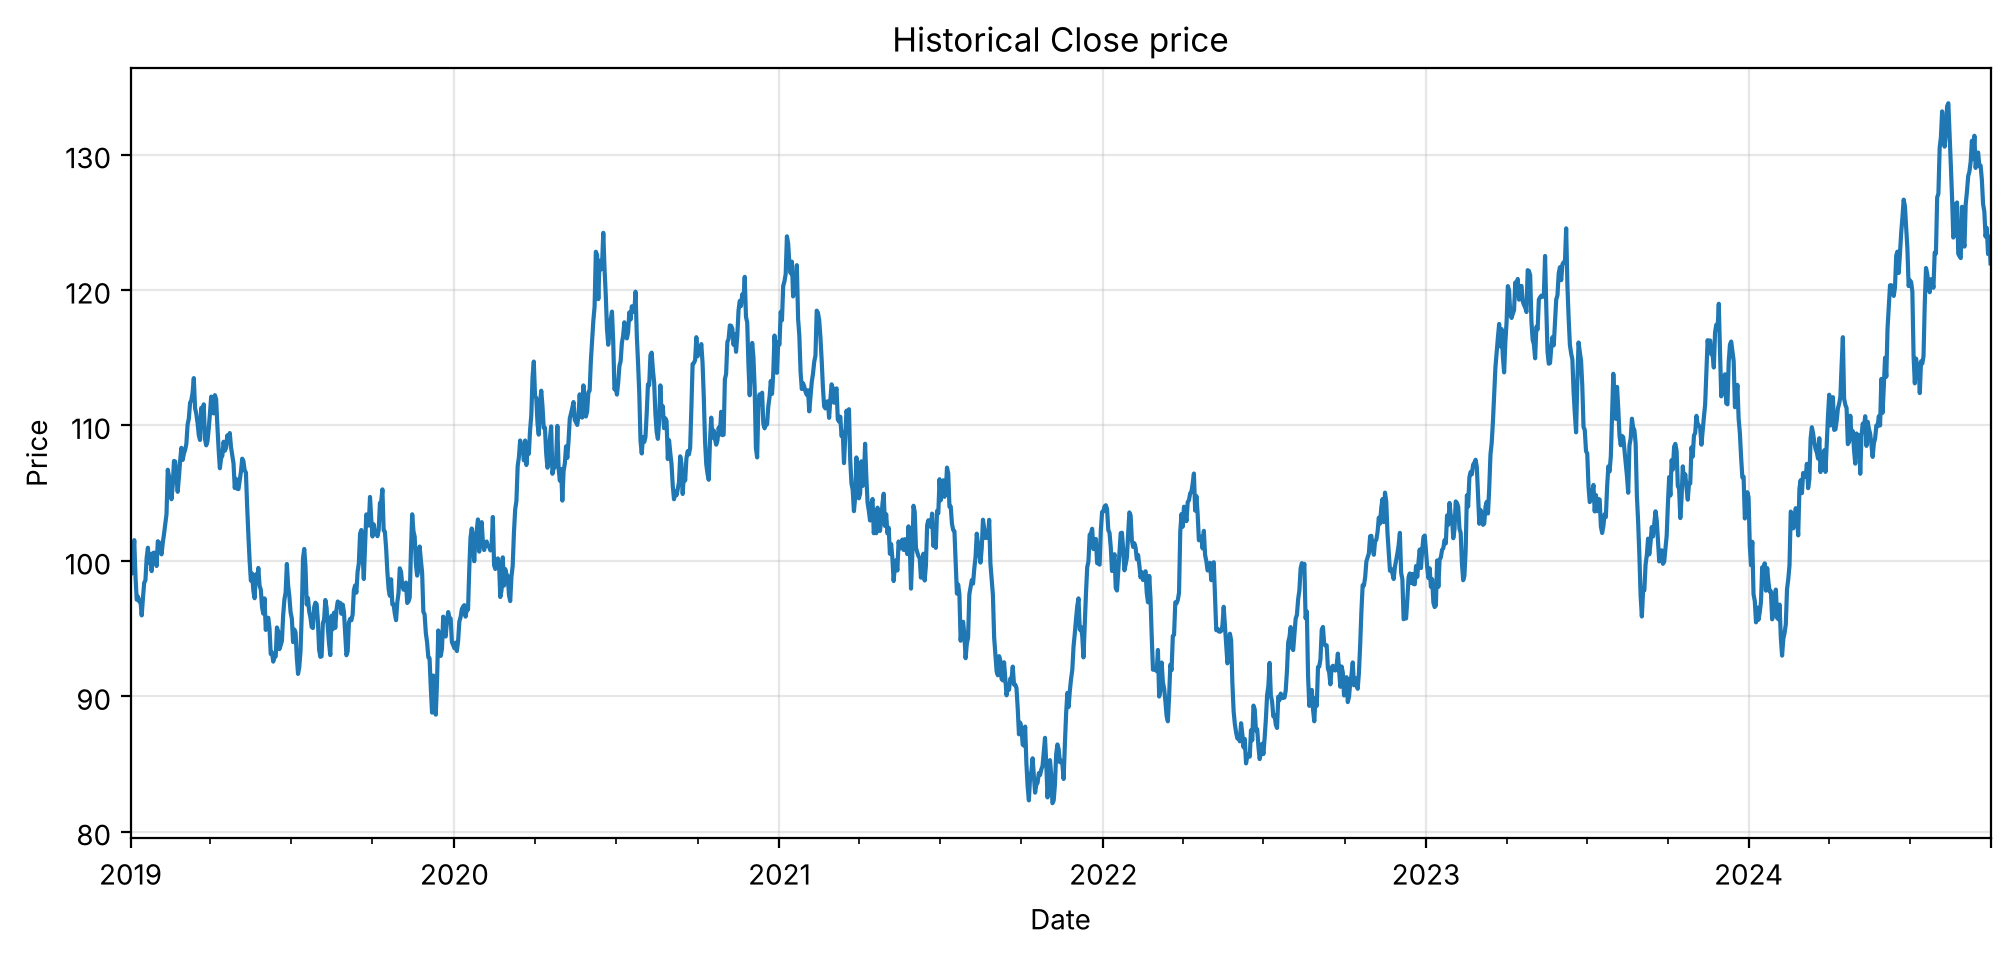

In [3]:
df[TARGET].plot(title=f"Historical {TARGET} price", ylabel="Price")
plt.show()

## Step 2 — Split into train and test periods
Time series must be split **chronologically** (never shuffled) so the model never sees the future.

Train: 2019-01-01 -> 2023-08-07  (1200 rows)
Test : 2023-08-08 -> 2024-09-30  (300 rows)


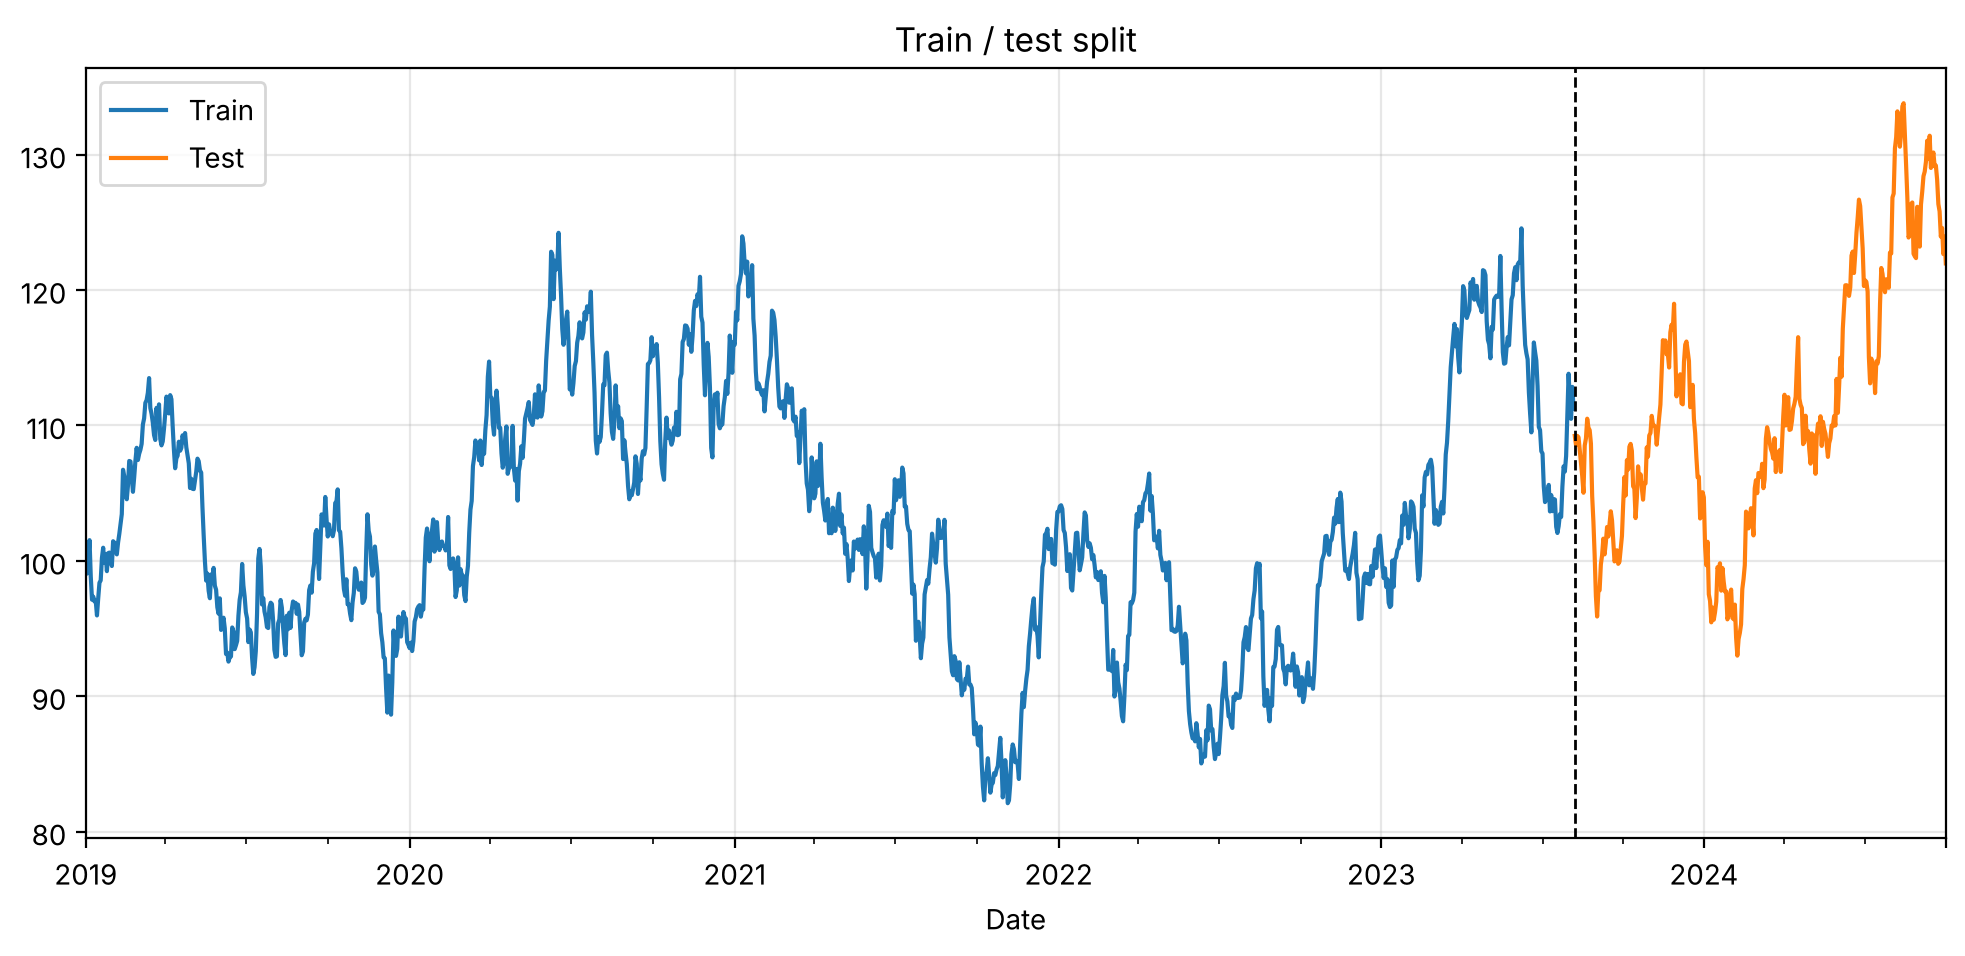

In [4]:
split_idx = int(len(df) * TRAIN_FRAC)
train, test = df.iloc[:split_idx], df.iloc[split_idx:]

print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} rows)")
print(f"Test : {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} rows)")

ax = train[TARGET].plot(label="Train")
test[TARGET].plot(ax=ax, label="Test")
ax.axvline(test.index[0], color="k", ls="--", lw=1)
ax.set_title("Train / test split"); ax.legend(); plt.show()

## Step 3 — Apply rolling-window moving average to predict
**One-step-ahead forecast:** prediction for day *t* = mean of the previous *W* actual closes.
`.shift(1)` guarantees day *t* never uses its own value (no data leakage).

The window size *W* is picked using **train MAE only**, so the test set stays untouched.

In [5]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))

def rolling_ma_forecast(series: pd.Series, window: int) -> pd.Series:
    """Predict each point as the mean of the previous `window` actual values."""
    return series.rolling(window=window).mean().shift(1)

# Forecast on the FULL series so the first test days can use the last train days as history
full = df[TARGET]
candidate_windows = [3, 5, 7, 10, 15, 20, 30, 50]

rows = []
for w in candidate_windows:
    pred = rolling_ma_forecast(full, w)
    p_train = pred.loc[train.index].dropna()
    rows.append({"window": w, "train_MAE": mae(train.loc[p_train.index, TARGET], p_train)})

window_search = pd.DataFrame(rows).set_index("window")
BEST_W = int(window_search["train_MAE"].idxmin())
print(f"Best window (by train MAE): {BEST_W}")
window_search.round(4)

Best window (by train MAE): 3


,train_MAE
window,
3,1.4822
5,1.7739
7,2.0213
10,2.3482
15,2.7937
20,3.1727
30,3.7104
50,4.4970


In [6]:
pred_full = rolling_ma_forecast(full, BEST_W)
test_pred = pred_full.loc[test.index]
test_actual = test[TARGET]
test_pred.head()

Date
2023-08-08    111.523333
2023-08-09    111.103333
2023-08-10    109.666667
2023-08-11    109.000000
2023-08-14    108.966667
Name: Close, dtype: float64

## Step 4 — Evaluate forecast error (MAE) on the test set

In [7]:
test_mae = mae(test_actual, test_pred)

# Naive baseline: predict yesterday's close
naive_pred = full.shift(1).loc[test.index]
naive_mae = mae(test_actual, naive_pred)

results = pd.DataFrame({
    "Model": [f"Rolling MA (window={BEST_W})", "Naive (yesterday's close)"],
    "Test MAE": [test_mae, naive_mae],
    "MAE as % of mean price": [100 * test_mae / test_actual.mean(), 100 * naive_mae / test_actual.mean()],
}).round(4)
results.to_csv(OUT_DIR / "metrics.csv", index=False)
results

,Model,Test MAE,MAE as % of mean price
0,Rolling MA (window=3),1.6653,1.4948
1,Naive (yesterday's close),1.3122,1.1779


## Step 5 — Plot actual vs predicted series

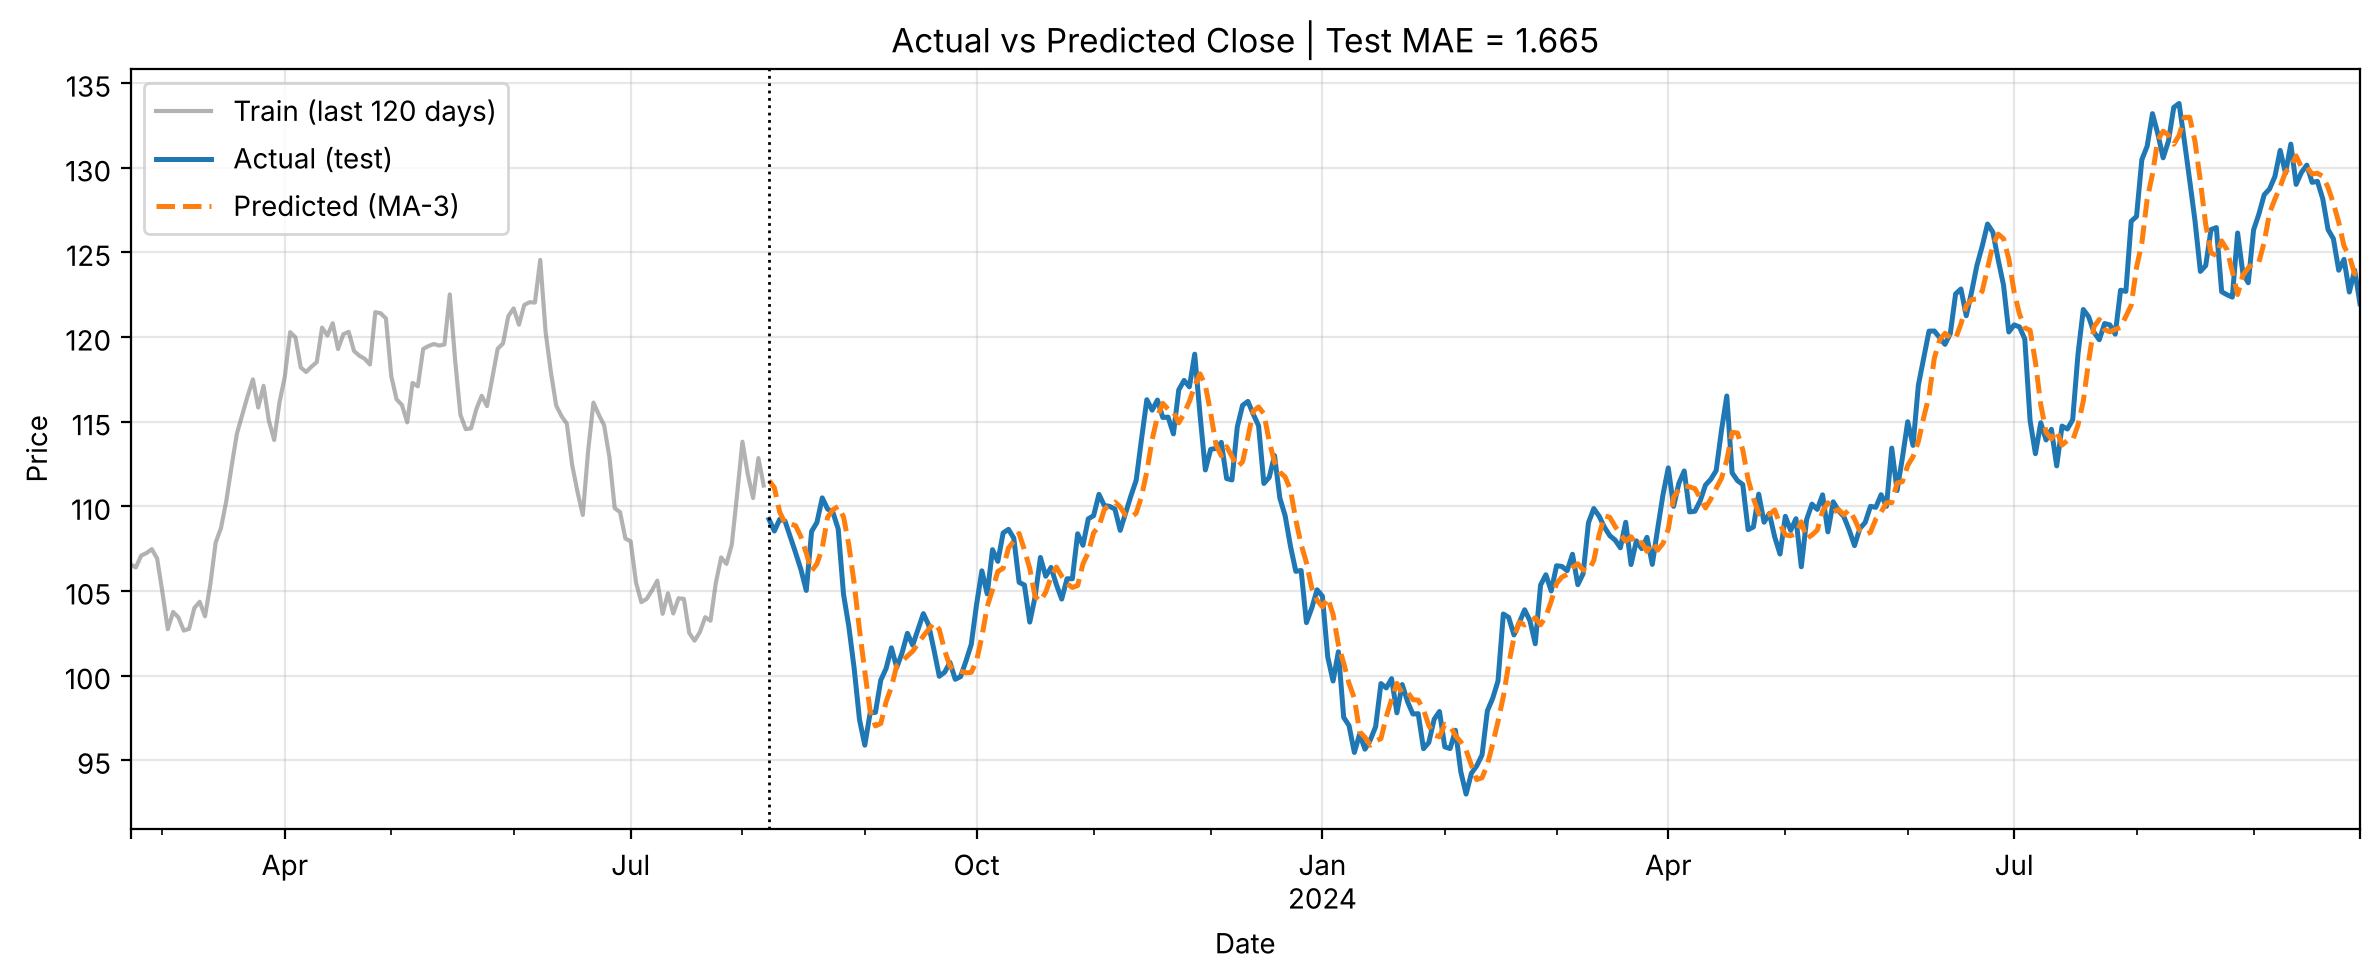

In [8]:
fig, ax = plt.subplots()
train[TARGET].iloc[-120:].plot(ax=ax, color="gray", alpha=0.6, label="Train (last 120 days)")
test_actual.plot(ax=ax, color="#1f77b4", lw=1.8, label="Actual (test)")
test_pred.plot(ax=ax, color="#ff7f0e", lw=1.8, ls="--", label=f"Predicted (MA-{BEST_W})")
ax.axvline(test.index[0], color="k", ls=":", lw=1)
ax.set_title(f"Actual vs Predicted {TARGET} | Test MAE = {test_mae:.3f}")
ax.set_ylabel("Price"); ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "forecast_plot.png", dpi=150)
plt.show()

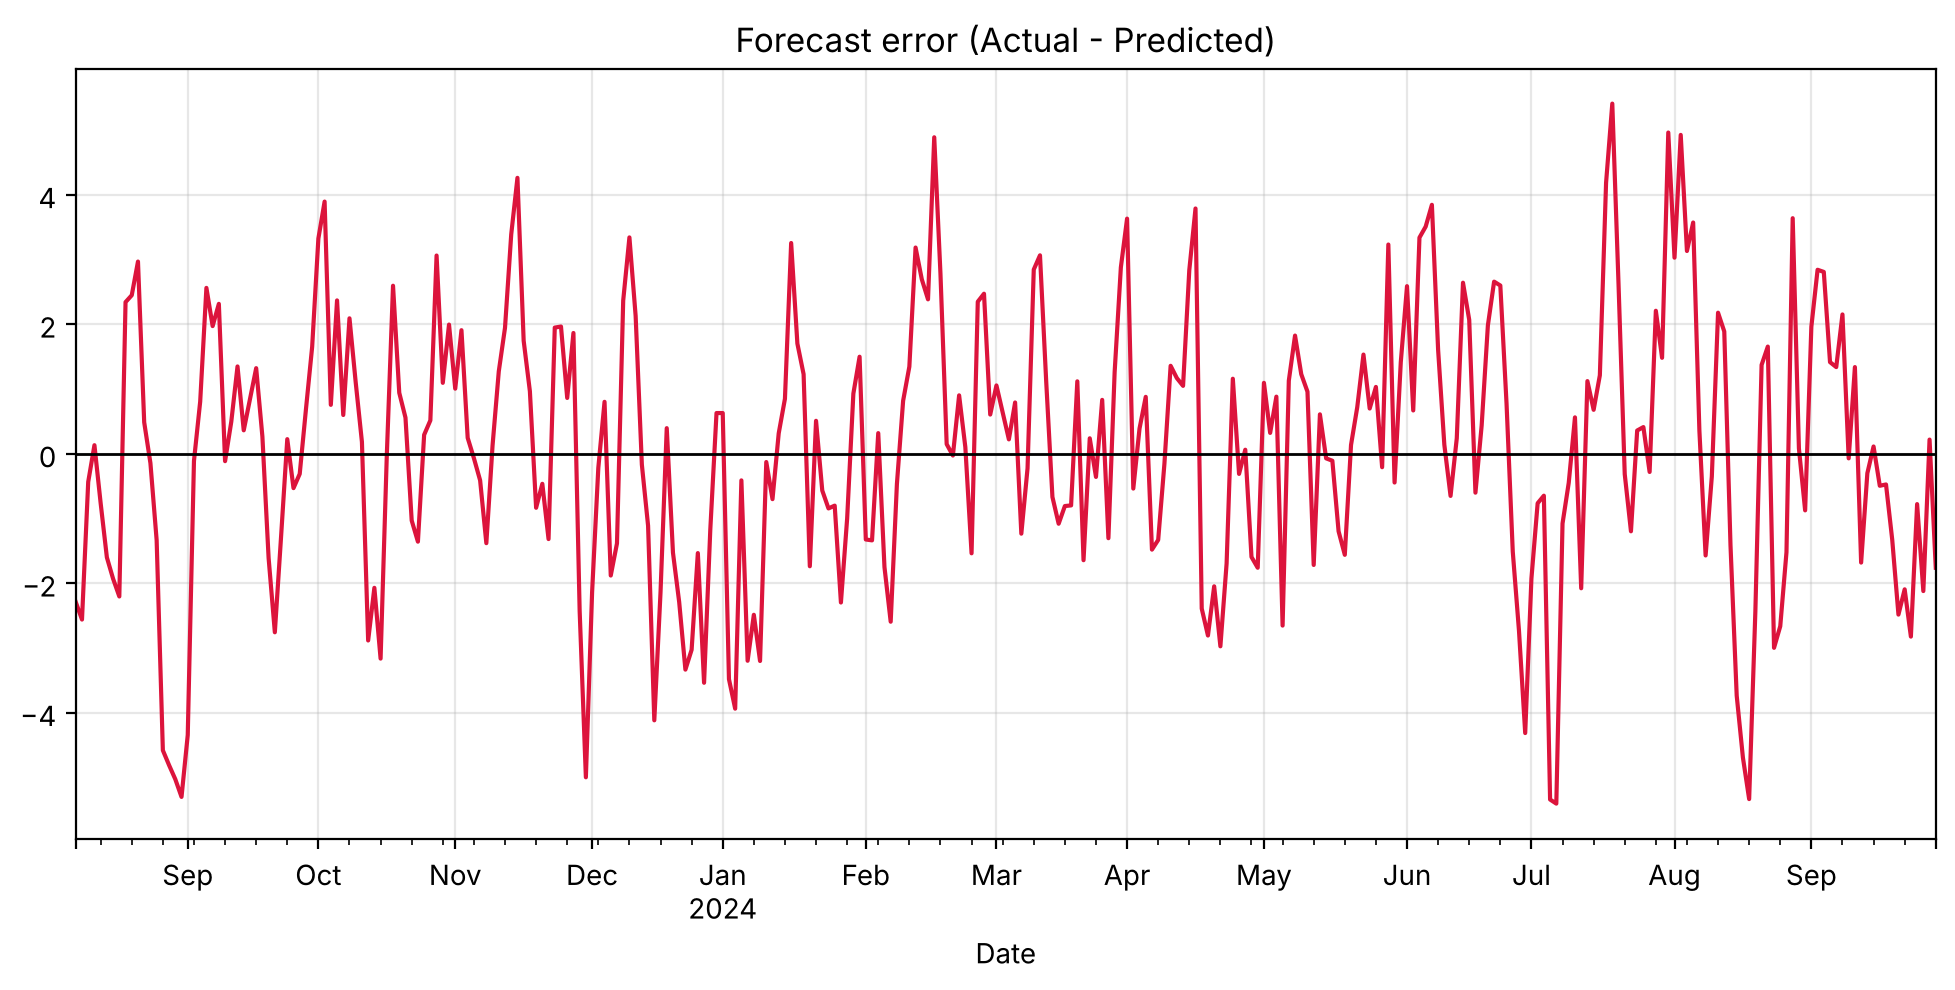

In [9]:
# Error over time - useful to spot where the moving average lags (trend changes / spikes)
err = (test_actual - test_pred)
ax = err.plot(color="crimson", title="Forecast error (Actual - Predicted)")
ax.axhline(0, color="k", lw=1); plt.show()

## Conclusion
- A rolling moving average **smooths noise** but **lags** behind trends, so it tends to under-predict in uptrends and over-predict in downtrends.
- Compare the MA's test MAE against the naive baseline above: if the MA doesn't beat it, a longer window is just adding lag.
- **Next steps:** exponential moving average (EMA), ARIMA / SARIMA, Prophet, or ML models (XGBoost, LSTM) with lag features.